# AdaBoost experiments

**Goal:** see how far AdaBoost gets on the classification task and which settings matter.

**Why AdaBoost:** there are 670 mostly numeric features, many of them redundant or constant. Boosted
shallow trees choose features as they go and don't need scaling, so they make a reasonable first
ensemble to try. AdaBoost also re-weights the examples it gets wrong, which may help with the
minority class (`output = 0`, about 15% of rows).

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

## 1. Load data

In [ ]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
sample_solution = pd.read_csv("sample_solution.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
train.output.value_counts(normalize=True)

Train shape: (4584, 670)
Test shape : (1732, 669)


output
1    0.844895
0    0.155105
Name: proportion, dtype: float64

## 2. Check how train and test subjects overlap

**Hypothesis:** `subject` looks like an ID for a person or device. If the test set has subjects that
aren't in training, a random K-fold split will overestimate the leaderboard score.

In [ ]:
subj = pd.DataFrame({
    "train": train.subject.value_counts(),
    "test": test.subject.value_counts(),
}).fillna(0).astype(int)
subj["train_frac_0"] = train.groupby("subject").output.apply(lambda s: (s == 0).mean()).round(3)
unseen = subj.index[subj.train == 0].tolist()
print("Subjects only in test:", unseen,
      f"-> {test.subject.isin(unseen).mean():.0%} of test rows")
subj

Subjects only in test: ['E', 'J'] -> 54% of test rows


,train,test,train_frac_0
subject,,,
A,380,59,0.029
B,513,78,0.140
C,361,71,0.244
D,420,83,0.062
E,0,312,NaN
F,330,60,0.221
G,518,88,0.508
H,181,33,0.138
I,663,124,0.038


**Interpretation:** subjects **E** and **J** appear only in the test set, and they make up over half of
it. The base rate also changes a lot between subjects (K has no 0s, G is about 50/50). So we:
- report **two CV scores**: stratified 5-fold (the optimistic one) and **GroupKFold by subject**
  (closer to what the unseen test subjects will look like). We pick settings using the grouped score.
- **leave `subject` out as a feature**, because it can't generalise to E and J.

## 3. Preprocessing

In [ ]:
target = "output"
groups = train["subject"]

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    X = pd.get_dummies(X, columns=["state"], dtype=int)
    return X

X_full = prep(train)
X_test = prep(test).reindex(columns=X_full.columns, fill_value=0)
y = train[target]

# Constant columns carry no signal and only slow the tree search down
const_cols = X_full.columns[X_full.nunique() <= 1]
X_full = X_full.drop(columns=const_cols)
X_test = X_test.drop(columns=const_cols)
print(f"Dropped {len(const_cols)} constant columns -> {X_full.shape[1]} features")

Dropped 108 constant columns -> 564 features


## 4. Evaluation harness and majority-class baseline

The competition metric is accuracy. Predicting all `1` already gets about 84.5%, so every model is
compared against that. We also track macro-F1 so we can see whether the minority class is being
learned at all.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
results = []

def evaluate(name, model):
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X_full, y, cv=cv, n_jobs=-1,
                           scoring=["accuracy", "f1_macro"], **kw)
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_acc_std"] = s["test_accuracy"].std()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
    results.append(row)
    return pd.Series(row)

evaluate("majority baseline", DummyClassifier(strategy="most_frequent"))

model            majority baseline
strat_acc                 0.844895
strat_acc_std             0.000424
strat_f1m                 0.457964
group_acc                 0.852051
group_acc_std               0.1156
group_f1m                  0.45784
dtype: object

## 5. Experiment 1: default AdaBoost (decision stumps)

**Hypothesis:** AdaBoost with depth-1 stumps and 50 rounds should beat the majority baseline, but 50
single-split learners are probably too weak for 500+ features.

In [ ]:
ada_default = AdaBoostClassifier(random_state=RANDOM_STATE)
evaluate("ada stumps, n=50, lr=1.0", ada_default)

model            ada stumps, n=50, lr=1.0
strat_acc                        0.847077
strat_acc_std                    0.002078
strat_f1m                        0.492495
group_acc                         0.84109
group_acc_std                    0.119586
group_f1m                         0.45557
dtype: object

**Interpretation:** default AdaBoost does **not** beat the baseline. Shuffled CV is only +0.2 pts
(0.847 vs 0.845). Grouped CV is about 1 pt *worse* (0.841 vs 0.852). Whatever the stumps learn
depends on the subject and doesn't carry over to subjects the model hasn't seen. The large grouped
std (about 0.12) comes from how much the class-0 rate differs between subjects, not from the model.

## 6. Experiment 2: number of rounds (staged learning curve)

**Hypothesis:** more rounds help up to a point, and then AdaBoost starts fitting noisy or mislabeled
points (it is known to be sensitive to label noise). A lower learning rate should push that peak
later and make it smoother.

`staged_predict` scores every prefix of the ensemble, so one fit per fold gives the whole curve. We
use the grouped folds.

In [7]:
def staged_curve(model, n_estimators):
    accs = np.zeros(n_estimators)
    for tr_idx, va_idx in gkf.split(X_full, y, groups):
        m = model.fit(X_full.iloc[tr_idx], y.iloc[tr_idx])
        for i, pred in enumerate(m.staged_predict(X_full.iloc[va_idx])):
            accs[i] += accuracy_score(y.iloc[va_idx], pred)
    return accs / gkf.get_n_splits()

N = 400
curves = {}
for depth in [1, 2, 3]:
    for lr in [1.0, 0.3, 0.1]:
        m = AdaBoostClassifier(DecisionTreeClassifier(max_depth=depth),
                               n_estimators=N, learning_rate=lr, random_state=RANDOM_STATE)
        curves[(depth, lr)] = staged_curve(m, N)
        best = curves[(depth, lr)].argmax()
        print(f"depth={depth} lr={lr:<4} best grouped acc={curves[(depth, lr)][best]:.4f} at n={best + 1}")

/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.1

depth=1 lr=1.0  best grouped acc=0.8478 at n=1


/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.1

depth=1 lr=0.3  best grouped acc=0.8521 at n=3


/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.1

...

/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.1

depth=2 lr=1.0  best grouped acc=0.8359 at n=1


/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/ayoolanjoku/opt/anaconda3/envs/py_313_conda/lib/python3.1

depth=2 lr=0.3  best grouped acc=0.8514 at n=37


KeyboardInterrupt: 

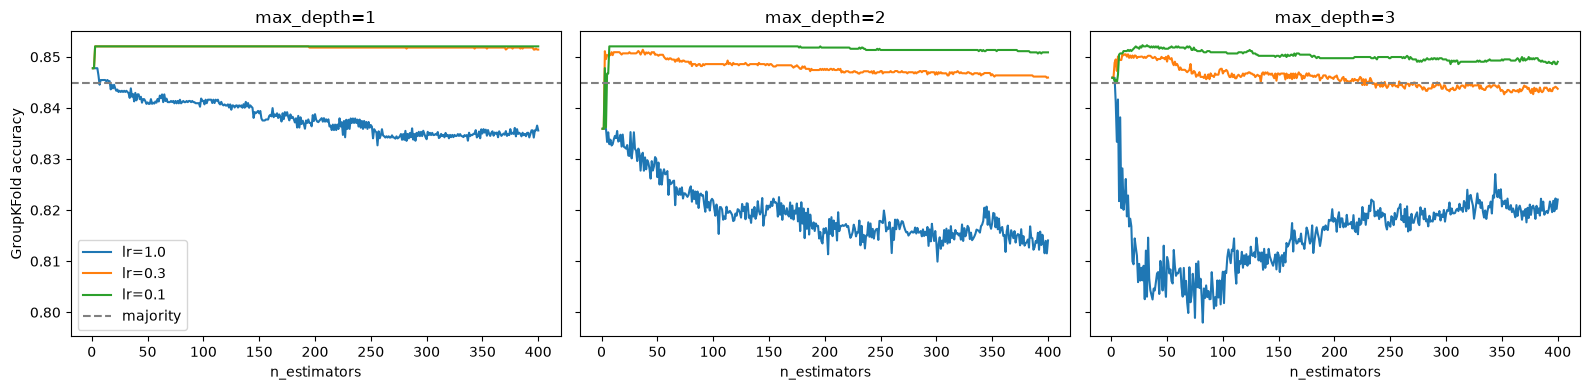

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
baseline_acc = (y == 1).mean()
for ax, depth in zip(axes, [1, 2, 3]):
    for lr in [1.0, 0.3, 0.1]:
        ax.plot(np.arange(1, N + 1), curves[(depth, lr)], label=f"lr={lr}")
    ax.axhline(baseline_acc, color="grey", ls="--", label="majority")
    ax.set_title(f"max_depth={depth}")
    ax.set_xlabel("n_estimators")
axes[0].set_ylabel("GroupKFold accuracy")
axes[0].legend()
plt.tight_layout()

**Interpretation:** this hypothesis was wrong. No setting does meaningfully better than the majority
baseline (0.852) on grouped CV:
- With lr=1.0, every depth peaks at **n=1** and then gets worse. More rounds only fit
  subject-specific noise.
- Lower learning rates just stay flat at the baseline, because the ensemble keeps predicting
  class 1. The best setting (depth=3, lr=0.1, n=28) gets 0.8523 vs 0.8521.

So under these features, AdaBoost finds no class-0 signal that transfers between subjects.

## 7. Experiment 3: confirm the best setting on both CV schemes

In [ ]:
(best_depth, best_lr), best_curve = max(curves.items(), key=lambda kv: kv[1].max())
best_n = int(best_curve.argmax()) + 1
print(f"Best: depth={best_depth}, lr={best_lr}, n_estimators={best_n}")

ada_best = AdaBoostClassifier(DecisionTreeClassifier(max_depth=best_depth),
                              n_estimators=best_n, learning_rate=best_lr,
                              random_state=RANDOM_STATE)
evaluate(f"ada depth={best_depth}, n={best_n}, lr={best_lr}", ada_best)
pd.DataFrame(results).set_index("model").round(4)

Best: depth=3, lr=0.1, n_estimators=28


,strat_acc,strat_acc_std,strat_f1m,group_acc,group_acc_std,group_f1m
model,,,,,,
majority baseline,0.8449,0.0004,0.4580,0.8521,0.1156,0.4578
"ada stumps, n=50, lr=1.0",0.8471,0.0021,0.4925,0.8411,0.1196,0.4556
"ada depth=3, n=28, lr=0.1",0.8466,0.0015,0.4734,0.8523,0.1155,0.4591


## 8. Experiment 4: errors on a held-out subject split

**Hypothesis:** almost all of the errors will be on the minority class (0), because the boosted
ensemble leans toward the 85% majority.

Held-out subjects: ['C', 'I']
accuracy=0.8896  macro-F1=0.4708


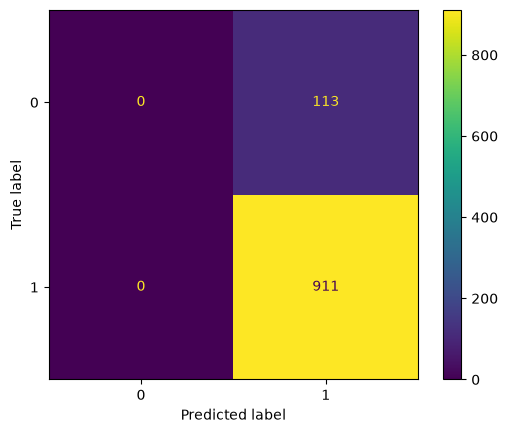

In [ ]:
gss_tr, gss_va = next(GroupKFold(n_splits=4).split(X_full, y, groups))
ada_best.fit(X_full.iloc[gss_tr], y.iloc[gss_tr])
pred = ada_best.predict(X_full.iloc[gss_va])
print("Held-out subjects:", sorted(groups.iloc[gss_va].unique()))
print(f"accuracy={accuracy_score(y.iloc[gss_va], pred):.4f}  "
      f"macro-F1={f1_score(y.iloc[gss_va], pred, average='macro'):.4f}")
ConfusionMatrixDisplay(confusion_matrix(y.iloc[gss_va], pred)).plot()

**Interpretation:** the confusion matrix is `[[0, 113], [0, 911]]`. The model predicts **class 1 for
every row**, so recall on class 0 is 0. Its 0.89 accuracy comes entirely from the held-out subjects
(C, I) being mostly class 1. Moving the threshold or reweighting classes would make it predict some
0s. Whether that raises accuracy depends on there being a real ranking signal underneath, which
section 9 suggests there isn't.

## 9. Feature importance

The grade includes 10% for explainability. We look at two views:
- **Impurity importance** (`feature_importances_`): cheap to compute, but biased toward features with
  many unique values.
- **Permutation importance** on the held-out subjects: how much accuracy drops when a feature is
  shuffled. This is more reliable, and it is measured on unseen subjects.

**Hypothesis:** a small set of features does most of the work, because AdaBoost with shallow trees
only ever splits on a few of them.

Features ever used: 64 / 564


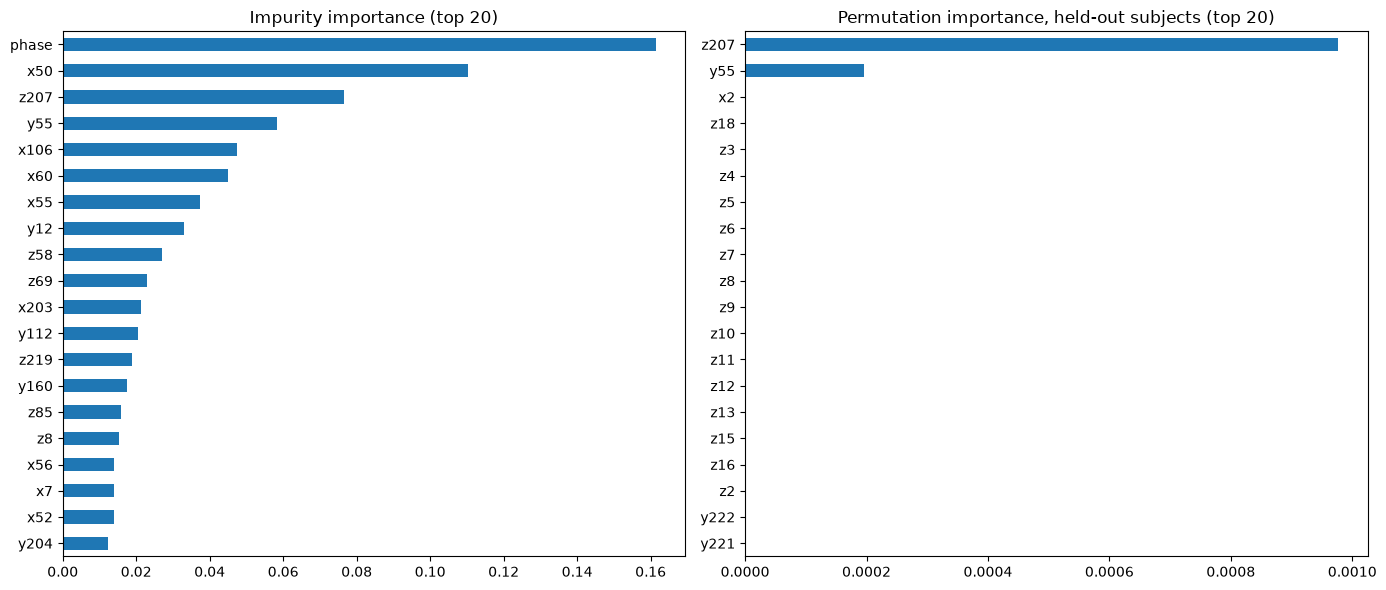

In [ ]:
imp = pd.Series(ada_best.feature_importances_, index=X_full.columns).sort_values(ascending=False)
print(f"Features ever used: {(imp > 0).sum()} / {len(imp)}")

perm = permutation_importance(ada_best, X_full.iloc[gss_va], y.iloc[gss_va],
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_full.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(20)[::-1].plot.barh(ax=axes[0], title="Impurity importance (top 20)")
perm_imp.head(20)[::-1].plot.barh(ax=axes[1], title="Permutation importance, held-out subjects (top 20)")
plt.tight_layout()

**Interpretation:** the two views disagree, which is a warning sign.
- By impurity, the top features are `phase`, `x50`, `z207`, `y55` and `x106`, and only 64 of 564
  features are used.
- By permutation on held-out subjects, nearly everything is about 0 (z207 is the highest at 0.001).

Because the model predicts all 1s on new subjects, shuffling any feature changes nothing. The
features it splits on in training are separating subjects, not classes.

## 10. Fit on all training data and write a submission

In [ ]:
ada_best.fit(X_full, y)
submission = sample_solution.copy()
submission["output"] = ada_best.predict(X_test)
submission.to_csv("submission_adaboost.csv", index=False)
print(submission.output.value_counts(normalize=True))

output
1    0.998845
0    0.001155
Name: proportion, dtype: float64


## Summary and next steps

**Result:** AdaBoost doesn't beat the majority-class baseline on grouped CV (best 0.8523 vs
0.8521). On held-out subjects it predicts all 1s. The submission (`submission_adaboost.csv`) is
therefore about the same as all 1s.

**What we learned:** the raw features seem to carry mostly *subject identity*, not class signal
that transfers between subjects. Tuning more boosting hyperparameters won't fix that.

**Next steps, most promising first:**
1. **Per-subject normalisation:** z-score each feature within its subject, for both train and
   test, so the model sees changes relative to each person's own baseline. This directly targets
   the problem found here.
2. Re-run this harness with that normalisation, then try threshold tuning for class 0.
3. Compare gradient boosting or random forest under the same GroupKFold harness.

*Runtime note:* section 6 takes about 75 min. Every peak was at n ≤ 37, so `N = 100` is enough for
re-runs.